In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("/content/drive/MyDrive/XAI-Stability-Bench/datasets/titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


imported titanic dataset and printed first 5 rows

In [4]:
df.shape

(891, 12)

In [5]:
df.columns


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [9]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

dropped some coumns which did not have any direct relations with the fact that some people survived and others did not

In [10]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [12]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [13]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

Filled the blank cells

In [14]:
from sklearn.preprocessing import LabelEncoder

In [15]:
label_encoder = LabelEncoder()
df["Sex"] = label_encoder.fit_transform(df["Sex"])

In [16]:
df = pd.get_dummies(df, columns=["Embarked"], dtype=int)

encoded embarked and sex colums

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    int64  
 3   Age         891 non-null    float64
 4   SibSp       891 non-null    int64  
 5   Parch       891 non-null    int64  
 6   Fare        891 non-null    float64
 7   Embarked_C  891 non-null    int64  
 8   Embarked_Q  891 non-null    int64  
 9   Embarked_S  891 non-null    int64  
dtypes: float64(2), int64(8)
memory usage: 69.7 KB


In [18]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,22.0,1,0,7.2500,0,0,1
1,1,1,0,38.0,1,0,71.2833,1,0,0
2,1,3,0,26.0,0,0,7.9250,0,0,1
3,1,1,0,35.0,1,0,53.1000,0,0,1
4,0,3,1,35.0,0,0,8.0500,0,0,1


# Model
## 1. Separate Features and Target

In [19]:
X = df.drop("Survived", axis=1)
y = df["Survived"]

In [20]:
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,3,1,22.0,1,0,7.2500,0,0,1
1,1,0,38.0,1,0,71.2833,1,0,0
2,3,0,26.0,0,0,7.9250,0,0,1
3,1,0,35.0,1,0,53.1000,0,0,1
4,3,1,35.0,0,0,8.0500,0,0,1


In [21]:
y.head()

,Survived
0,0
1,1
2,1
3,1
4,0


## 2. Split the Dataset


In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [23]:
print(X_train.shape)
print(X_test.shape)

(712, 9)
(179, 9)


## 3. Feature Scaling
Logistic Regression works better if numerical features are on similar scales.

In [24]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 4. Train Logistic Regression

In [25]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

LogisticRegression(random_state=42)

## 5. Generate Predictions

In [26]:
y_pred = model.predict(X_test)

## 6. Evaluate Model Performance

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.8101
Precision: 0.7857
Recall   : 0.7432
F1 Score : 0.7639


## 7. Confusion Matrix

In [28]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[90 15]
 [19 55]]


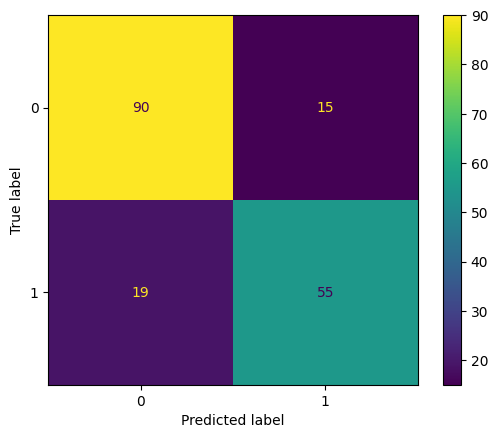

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

In [30]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



In [31]:
import joblib

joblib.dump(
    model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/logistic_regression.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/logistic_regression.pkl']

In [32]:
df.to_csv(
    "/content/drive/MyDrive/XAI-Stability-Bench/datasets/titanic_preprocessed.csv",
    index=False
)
df = pd.read_csv(
    "/content/drive/MyDrive/XAI-Stability-Bench/datasets/titanic_preprocessed.csv"
)

## Decision Tree

In [33]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1 Score : {dt_f1:.4f}")

Accuracy : 0.7877
Precision: 0.7308
Recall   : 0.7703
F1 Score : 0.7500


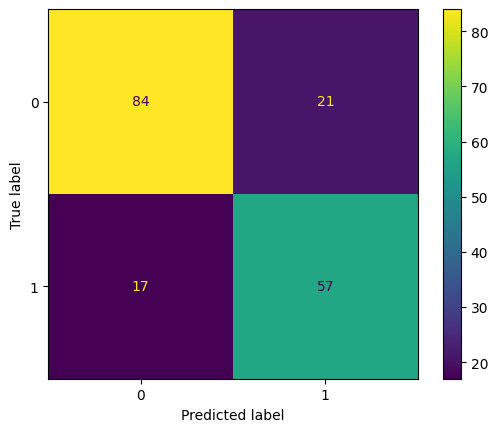

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred
)

In [35]:
from sklearn.metrics import classification_report

print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           0       0.83      0.80      0.82       105
           1       0.73      0.77      0.75        74

    accuracy                           0.79       179
   macro avg       0.78      0.79      0.78       179
weighted avg       0.79      0.79      0.79       179



In [36]:
import joblib

joblib.dump(
    dt_model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/decision_tree.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/decision_tree.pkl']

## Random Forest

In [37]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")

Accuracy : 0.8045
Precision: 0.7671
Recall   : 0.7568
F1 Score : 0.7619


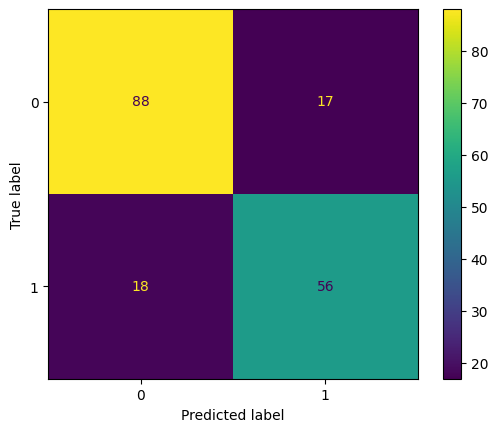

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred
)

In [39]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.83      0.84      0.83       105
           1       0.77      0.76      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.80      0.80      0.80       179



In [40]:
import joblib

joblib.dump(
    rf_model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/random_forest.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/random_forest.pkl']

## Dictionary of results for future use


In [41]:
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": round(accuracy, 4),
    "Precision": round(precision, 4),
    "Recall": round(recall, 4),
    "F1 Score": round(f1, 4)
}

dt_results = {
    "Model": "Decision Tree",
    "Accuracy": round(dt_accuracy, 4),
    "Precision": round(dt_precision, 4),
    "Recall": round(dt_recall, 4),
    "F1 Score": round(dt_f1, 4)
}

rf_results = {
    "Model": "Random Forest",
    "Accuracy": round(rf_accuracy, 4),
    "Precision": round(rf_precision, 4),
    "Recall": round(rf_recall, 4),
    "F1 Score": round(rf_f1, 4)
}

XGBoost

In [42]:
!pip install xgboost

In [43]:
from xgboost import XGBClassifier

In [44]:
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

In [45]:
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)
print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")

Accuracy : 0.7933
Precision: 0.7534
Recall   : 0.7432
F1 Score : 0.7483


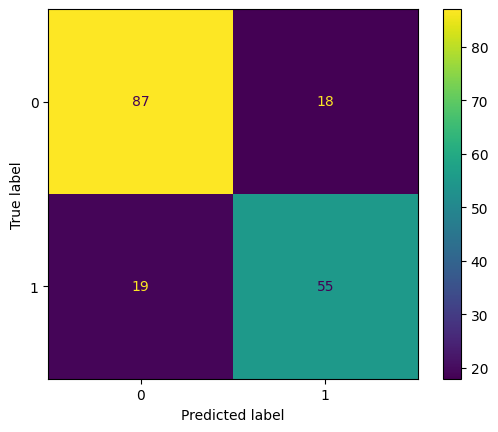

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred
)

In [47]:
from sklearn.metrics import classification_report

print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.82       105
           1       0.75      0.74      0.75        74

    accuracy                           0.79       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.79      0.79      0.79       179



In [48]:
import joblib

joblib.dump(
    xgb_model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/xgboost.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/xgboost.pkl']

In [49]:
xgb_results = {
    "Model": "XGBoost",
    "Accuracy": round(xgb_accuracy, 4),
    "Precision": round(xgb_precision, 4),
    "Recall": round(xgb_recall, 4),
    "F1 Score": round(xgb_f1, 4)
}

In [50]:
import pandas as pd

results_df = pd.DataFrame([
    lr_results,
    dt_results,
    rf_results,
    xgb_results
])

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8101,0.7857,0.7432,0.7639
1,Decision Tree,0.7877,0.7308,0.7703,0.7500
2,Random Forest,0.8045,0.7671,0.7568,0.7619
3,XGBoost,0.7933,0.7534,0.7432,0.7483


In [51]:
results_df.to_csv(
    "/content/drive/MyDrive/XAI-Stability-Bench/results/titanic_model_comparison.csv",
    index=False
)

In [52]:
from sklearn.metrics import roc_auc_score

#For Logistic Regression:

lr_auc = roc_auc_score(
    y_test,
    model.predict_proba(X_test)[:, 1]
)

print(f"ROC-AUC: {lr_auc:.4f}")

#For Decision Tree:

dt_auc = roc_auc_score(
    y_test,
    dt_model.predict_proba(X_test)[:, 1]
)

#For Random Forest:

rf_auc = roc_auc_score(
    y_test,
    rf_model.predict_proba(X_test)[:, 1]
)

#For XGBoost:

xgb_auc = roc_auc_score(
    y_test,
    xgb_model.predict_proba(X_test)[:, 1]
)

lr_results["ROC-AUC"] = round(lr_auc, 4)
dt_results["ROC-AUC"] = round(dt_auc, 4)
rf_results["ROC-AUC"] = round(rf_auc, 4)
xgb_results["ROC-AUC"] = round(xgb_auc, 4)

ROC-AUC: 0.8820


In [53]:
import pandas as pd

results_df = pd.DataFrame([
    lr_results,
    dt_results,
    rf_results,
    xgb_results
])
results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8101,0.7857,0.7432,0.7639,0.8820
1,Decision Tree,0.7877,0.7308,0.7703,0.7500,0.8055
2,Random Forest,0.8045,0.7671,0.7568,0.7619,0.8905
3,XGBoost,0.7933,0.7534,0.7432,0.7483,0.8664


In [54]:
results_df.to_csv(
    "/content/drive/MyDrive/XAI-Stability-Bench/results/titanic_model_comparison.csv",
    index=False
)
import os

os.path.exists("/content/drive/MyDrive/XAI-Stability-Bench/results/titanic_model_comparison.csv")

True